# Классификация MRI-снимков: собственная CNN и ResNet18

**Задача:** классифицировать MRI-изображения по четырём классам: `glioma`, `meningioma`, `notumor`, `pituitary`.

Порядок работы: загрузка данных → подготовка выборок → обучение собственной CNN → обучение предобученной ResNet18 → сравнение результатов.

> Это учебный эксперимент, не предназначенный для медицинской диагностики.


## 1. Установка и импорт библиотек

In [ ]:
#%pip install kagglehub scikit-learn seaborn torchvision pillow -q

In [ ]:
import os, random, time, copy
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support


In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

Устройство: cpu


## 2. Загрузка датасета

In [ ]:
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
TRAIN_DIR = os.path.join(path, "Training")
TEST_DIR = os.path.join(path, "Testing")

# Названия подпапок соответствуют классам изображений
classes = sorted([
    name for name in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, name))
])
print("Классы:", classes)


100%|██████████| 157M/157M [00:01<00:00, 132MB/s]

Extracting files...


Классы: ['glioma', 'meningioma', 'notumor', 'pituitary']


## 3. Загрузка изображений и первичный просмотр

Training: (5600, 128, 128, 3) | Testing: (1600, 128, 128, 3)


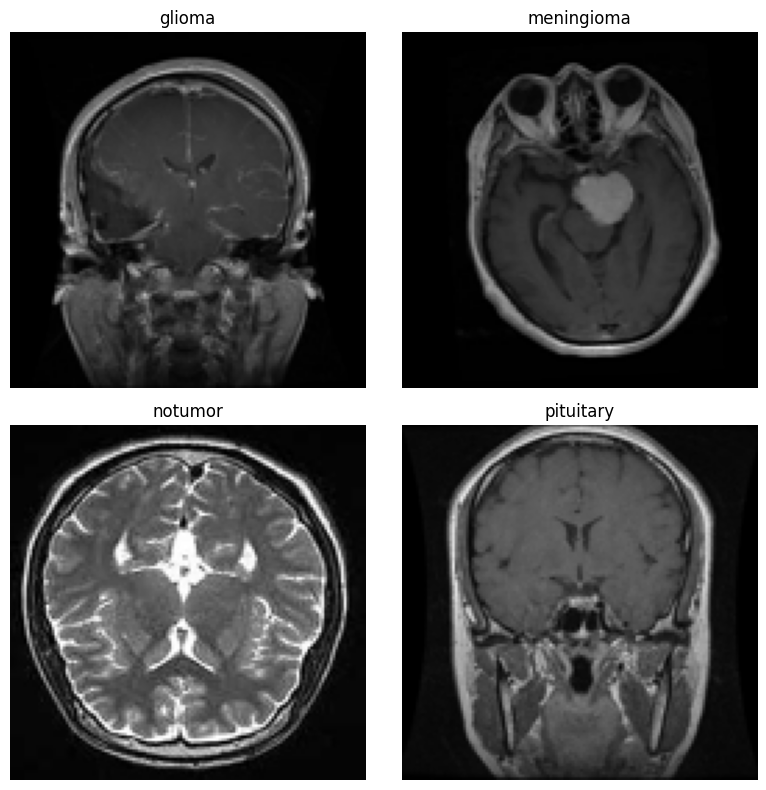

In [ ]:
# задаем размер изображениям, чтобы картинки можно было объединять в батчи
IMG_SIZE = 128

# функция для загрузки изображений
def load_folder(root):
    images, labels = [], []

    # перебираем каждый класс
    for cls in classes:
        folder = os.path.join(root, cls)

        for name in sorted(os.listdir(folder)):
            file_path = os.path.join(folder, name)
            if not os.path.isfile(file_path):
                continue
            # открываем и обрабатываем изображения
            try:
                with Image.open(file_path) as img:
                    img = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
                    images.append(np.asarray(img, dtype=np.uint8))
                    labels.append(cls)
            except Exception as error:
                print("Пропущен файл:", file_path, error)
    return np.asarray(images, dtype=np.uint8), np.asarray(labels)

X_train_all, y_train_all = load_folder(TRAIN_DIR)
X_test, y_test = load_folder(TEST_DIR)
print("Training:", X_train_all.shape, "| Testing:", X_test.shape)

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for ax, cls in zip(axes.ravel(), classes):
    idx = np.where(y_train_all == cls)[0][0]
    ax.imshow(X_train_all[idx])
    ax.set_title(cls)
    ax.axis("off")
plt.tight_layout()
plt.show()




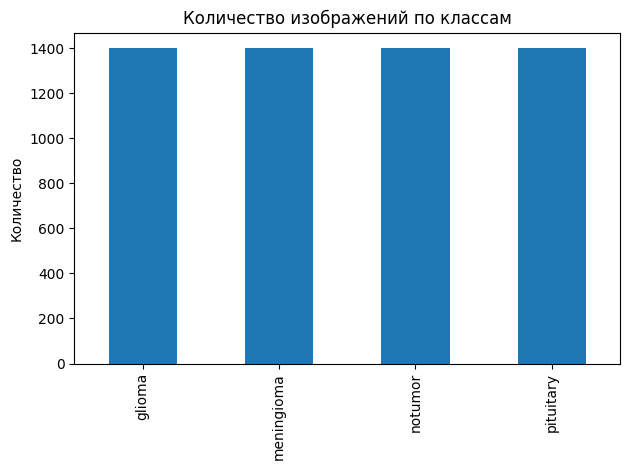

In [ ]:
# смотрим сколько изображений в каждом классе (столбчатая диаграмма распределения изображений по классам)
pd.Series(y_train_all).value_counts().reindex(classes).plot(
    kind="bar", title="Количество изображений по классам"
)
plt.ylabel("Количество")
plt.tight_layout()
plt.show()

# датасет сбалансирован

## 4. Train / Val split и Dataset

In [ ]:
#преобразуем названия классов в числа
encoder = LabelEncoder()
encoder.fit(classes) # настройка кодировщика, запоминает классы и их соответствие числам
class_names = list(encoder.classes_)
num_classes = len(class_names) # задаем количество классов
y_train_all = encoder.transform(y_train_all)
y_test = encoder.transform(y_test)

# разделяем данные на обучающую и валидационную выборки
X_train, X_val, y_train, y_val = train_test_split(
    X_train_all,
    y_train_all,
    test_size=0.2,  # 20% данных в валидационную выборку, 80% в обучающую
    random_state=SEED,
    stratify=y_train_all
)
print(f"обучающая: {len(X_train)}, валидационная: {len(X_val)}, test: {len(X_test)}")

# по train рассчитываем нормализацию для собственной CNN
train_float = X_train.astype(np.float32) / 255
cnn_mean = train_float.mean(axis=(0, 1, 2)).tolist()
cnn_std = train_float.std(axis=(0, 1, 2)).tolist()
cnn_std = [x if x > 1e-6 else 1.0 for x in cnn_std]
# После этого значения будут центрированы относительно среднего и масштабированы с учётом разброса

cnn_train_transform = T.Compose([
    T.ToPILImage(),  # преобразует массив NumPy в изображение PIL
    T.RandomHorizontalFlip(), # случайным образом отражает картинку по горизонтали
    T.RandomRotation(8), # случайным образом поворачивает её в пределах примерно от −8 до +8 градусов
    T.ToTensor(), # превращает изображение в тензор PyTorch и переводит значения пикселей в диапазон от 0 до 1
    T.Normalize(cnn_mean, cnn_std) # превращает изображение в тензор PyTorch и переводит значения пикселей в диапазон от 0 до 1
])
cnn_eval_transform = T.Compose([
    T.ToPILImage(), T.ToTensor(), T.Normalize(cnn_mean, cnn_std)
])


обучающая: 4480, валидационная: 1120, test: 1600


In [ ]:
# подготавливаем изображения для ResNet18
# ResNet18 использует стандартную нормализацию ImageNet.
resnet_train_transform = T.Compose([
    T.ToPILImage(), T.RandomHorizontalFlip(), T.RandomRotation(8),
    T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
resnet_eval_transform = T.Compose([
    T.ToPILImage(),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], # средние значения R, G, B
                [0.229, 0.224, 0.225]) # стандартные отклонения R, G, B
])

In [ ]:
# создаем класс датасета
class MRI_Dataset(Dataset):

    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.transform(self.images[idx]), int(self.labels[idx])

#количество изображений, которые модель обрабатывает за один шаг обучения
BATCH_SIZE = 32


# создаем загрузчики данных
def make_loaders(train_transform, eval_transform):

    train_loader = DataLoader(
        MRI_Dataset(X_train, y_train, train_transform),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=0
    )

    val_loader = DataLoader(
        MRI_Dataset(X_val, y_val, eval_transform),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )
    test_loader = DataLoader(
        MRI_Dataset(X_test, y_test, eval_transform),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )
    return train_loader, val_loader, test_loader

# создаём загрузчики для обеих моделей
train_cnn, val_cnn, test_cnn = make_loaders(cnn_train_transform, cnn_eval_transform)
train_resnet, val_resnet, test_resnet = make_loaders(resnet_train_transform, resnet_eval_transform)


## 5. обучаем собственную CNN

Conv2d - свертка

находит полезные признаки изображения. сначала простые границы и контуры, а на более глубоких этапах более сложные структуры.

BatchNorm2d - нормализация
Нормализует значения признаков внутри батча. помогает стабилизировать обучение.

ReLU - функция активации

заменяет отрицательные значения нулями, положительные оставляет без изменений.

MaxPool2d(2) - уменьшение размера

разбивает карту признаков на области 2 × 2 и оставляет максимальное значение из каждой области. при стандартном шаге 2 уменьшает высоту и ширину вдвое, сохраняя количество каналов.

In [ ]:
class SimpleCNN(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        # sequental позволяет объединить слои в последовательность
        self.features = nn.Sequential(

            #  4 свёрточных этапа
            # каждый состоит из свёртки, нормализации, активации и уменьшения размера изображения
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128),
            nn.ReLU(), nn.MaxPool2d(2)
        )

        # создаем классификатор
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )

    # определяем, как данные проходят через сеть
    def forward(self, x):
        return self.classifier(self.features(x))

# создаем моедль и выводим ее структуру
cnn_model = SimpleCNN(num_classes).to(device)
print(cnn_model)


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

In [ ]:
# функция обучает модель обучения в течение одной эпохи
def train_epoch(model, loader, criterion, optimizer):

    model.train()
    total_loss, correct, total = 0, 0, 0

    # перебираем батчи
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad() # обнуляет предыдущие градиенты
        outputs = model(images)
        loss = criterion(outputs, labels) # функция потерь
        loss.backward()
        optimizer.step()

        # подсчитываем результаты обучения
        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)

    # возвращает среднюю ошибку, точность
    return total_loss / total, correct / total

# проверяет качество модели без обучения
@torch.no_grad() # отключает отслеживание градиентов внутри функции
def evaluate(model, loader, criterion):

    model.eval() # переводит модель в режим оценки

    # счетчики
    total_loss, correct, total = 0, 0, 0

    true_labels, predictions = [], []

    # изображения передаются в модель, вычисляется ошибка и определяется предсказанный класс
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        pred = outputs.argmax(1)
        total_loss += loss.item() * len(labels)
        correct += (pred == labels).sum().item()
        total += len(labels)
        true_labels.extend(labels.cpu().numpy())
        predictions.extend(pred.cpu().numpy())

    return total_loss / total, correct / total, np.array(true_labels),  np.array(predictions)   # массив правильных и предсказанных меток

# функция обучения и проверки качества
def fit(model, train_loader, val_loader, epochs, lr, patience=3, title="Model"):

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "time": []}
    best_loss, best_weights, wait = float("inf"), None, 0

    for epoch in range(epochs):
        start = time.time()
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)

        scheduler.step(val_loss)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["time"].append(time.time() - start)

        print(f"{title} | эпоха {epoch+1}/{epochs} | "
              f"train loss={train_loss:.4f}, acc={train_acc:.4f} | "
              f"val loss={val_loss:.4f}, acc={val_acc:.4f}")

        if val_loss < best_loss - 1e-4:
            best_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Остановка: validation loss больше не улучшается.")
                break
    if best_weights is not None:
        model.load_state_dict(best_weights)
    return history

# обучаем собственную сеть с нуля
history_cnn = fit(
    cnn_model, train_cnn, val_cnn,
    epochs=10, lr=1e-3, patience=3, title="SimpleCNN"
)


SimpleCNN | эпоха 1/10 | train loss=0.8292, acc=0.6645 | val loss=0.7420, acc=0.7027


## 6. Затем обучаем предобученную ResNet18

In [ ]:
# ResNet18 уже обучена на ImageNet
# меняем последний слой на 4 класса
resnet_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, num_classes)
resnet_model = resnet_model.to(device)

history_resnet = fit(
    resnet_model, train_resnet, val_resnet,
    epochs=8, lr=3e-4, patience=3, title="ResNet18"
)


## 7. Сравнение графиков обучения

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, history in [("SimpleCNN", history_cnn), ("ResNet18", history_resnet)]:
    axes[0].plot(history["train_loss"], "--", label=f"{name} train")
    axes[0].plot(history["val_loss"], label=f"{name} validation")
    axes[1].plot(history["train_acc"], "--", label=f"{name} train")
    axes[1].plot(history["val_acc"], label=f"{name} validation")
axes[0].set_title("Loss") # меньше - лучше
axes[1].set_title("Accuracy") #больше - лучше
for ax in axes:
    ax.set_xlabel("Эпоха")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()


## 8. Оценка и сравнение на тестовой выборке

In [ ]:
def test_report(model, loader, name):
    loss, accuracy, y_true, y_pred = evaluate(model, loader, nn.CrossEntropyLoss())
    print(f"\n{name}: test loss={loss:.4f}, accuracy={accuracy:.4f}")
    print(classification_report(
        y_true, y_pred, labels=np.arange(num_classes),
        target_names=class_names, digits=4, zero_division=0
    ))
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Предсказанный класс")
    plt.ylabel("Истинный класс")
    plt.title(f"Матрица ошибок — {name}")
    plt.tight_layout()
    plt.show()
    _, _, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    return {"Модель": name, "Test accuracy": accuracy, "Macro F1": f1, "Test loss": loss}

result_cnn = test_report(cnn_model, test_cnn, "SimpleCNN")


In [ ]:
result_resnet = test_report(resnet_model, test_resnet, "ResNet18")

In [ ]:
comparison = pd.DataFrame([result_cnn, result_resnet]).set_index("Модель")
display(comparison.round(4))

## 9. Примеры предсказаний

In [ ]:
@torch.no_grad()
def show_predictions(model, images, labels, transform, title, n=8):
    model.eval()
    indices = np.random.choice(len(images), min(n, len(images)), replace=False)
    fig, axes = plt.subplots(2, 4, figsize=(15, 7))
    axes = axes.ravel()
    for ax, idx in zip(axes, indices):
        x = transform(images[idx]).unsqueeze(0).to(device)
        probabilities = torch.softmax(model(x), dim=1)[0]
        pred = int(probabilities.argmax().item())
        true = int(labels[idx])
        ax.imshow(images[idx])
        ax.set_title(
            f"Истина: {class_names[true]}\n"
            f"Прогноз: {class_names[pred]} ({probabilities[pred].item():.2f})",
            color="green" if pred == true else "red"
        )
        ax.axis("off")
    for ax in axes[len(indices):]:
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_predictions(cnn_model, X_test, y_test, cnn_eval_transform, "Предсказания собственной CNN")
show_predictions(resnet_model, X_test, y_test, resnet_eval_transform, "Предсказания ResNet18")
